In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files
uploaded = files.upload()

Saving student-por.csv to student-por.csv


In [3]:
import pandas as pd

df = pd.read_csv('student-por.csv', sep=';')

print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (649, 33)


In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 649
Total Columns: 33


In [6]:
print(df.columns)

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [8]:
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [10]:
# Check outliers using IQR method

columns = ['age', 'absences', 'G1', 'G2', 'G3']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

age Outliers: 1
absences Outliers: 21
G1 Outliers: 16
G2 Outliers: 25
G3 Outliers: 16


In [11]:
cleaned_df = df.drop_duplicates()

print("Original Rows:", df.shape[0])
print("Cleaned Rows:", cleaned_df.shape[0])

Original Rows: 649
Cleaned Rows: 649


In [12]:
print(cleaned_df.isnull().sum().sum())

0


In [13]:
cleaned_df.to_csv("cleaned_student_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [14]:
from google.colab import files

files.download("cleaned_student_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

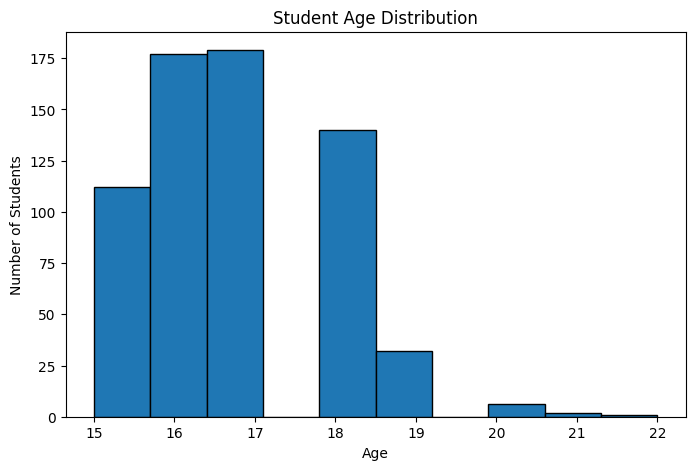

In [15]:
plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=10, edgecolor='black')

plt.title('Student Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Students')

plt.show()

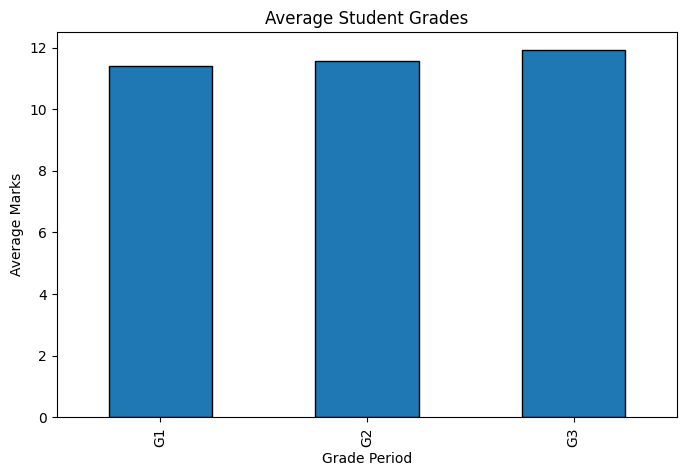

In [16]:
average_grades = df[['G1', 'G2', 'G3']].mean()

plt.figure(figsize=(8,5))

average_grades.plot(kind='bar', edgecolor='black')

plt.title('Average Student Grades')
plt.xlabel('Grade Period')
plt.ylabel('Average Marks')

plt.show()

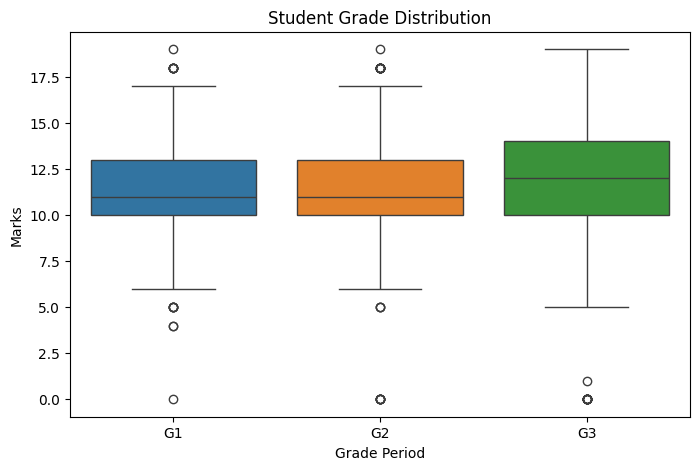

In [17]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df[['G1', 'G2', 'G3']])

plt.title('Student Grade Distribution')
plt.xlabel('Grade Period')
plt.ylabel('Marks')

plt.show()

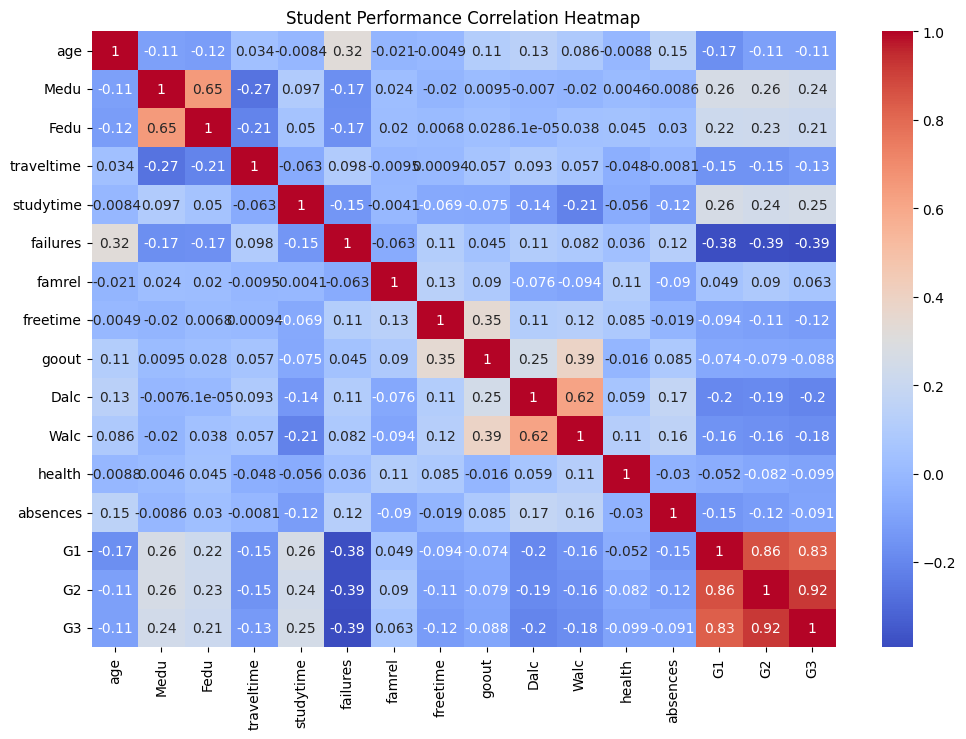

In [18]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Student Performance Correlation Heatmap')
plt.show()

In [19]:
print("STUDENT PERFORMANCE ANALYSIS")

print("\n1. Average Age:")
print(df['age'].mean())

print("\n2. Average Study Time:")
print(df['studytime'].mean())

print("\n3. Average First Period Grade:")
print(df['G1'].mean())

print("\n4. Average Second Period Grade:")
print(df['G2'].mean())

print("\n5. Average Final Grade:")
print(df['G3'].mean())

print("\n6. Highest Final Grade:")
print(df['G3'].max())

print("\n7. Lowest Final Grade:")
print(df['G3'].min())

STUDENT PERFORMANCE ANALYSIS

1. Average Age:
16.7442218798151

2. Average Study Time:
1.9306625577812018

3. Average First Period Grade:
11.399075500770415

4. Average Second Period Grade:
11.570107858243452

5. Average Final Grade:
11.906009244992296

6. Highest Final Grade:
19

7. Lowest Final Grade:
0


Data Analysis – Findings

1. The average study time of students is 1.93.
2. The average first-period grade (G1) is 11.40.
3. The average second-period grade (G2) is 11.57.
4. The average final grade (G3) is 11.91.
5. The highest final grade recorded is 19.
6. The lowest final grade recorded is 0.
7. The average grades show a slight increase across the three examination periods.

Conclusion

The Student Performance Dataset was successfully analyzed using Python. Data cleaning checks were performed to identify missing values and duplicate records. Statistical analysis and visualizations were used to understand student performance. The project helped demonstrate data preprocessing, data visualization, and data analysis using Pandas, Matplotlib, and Seaborn.